#### Exploratory Data Analysis.
##### Phase of a detective for the dataset.
- Business Decissions
- know the data in-out

#### Why Eda?
- Catches hidden errors : (detect missing values,typos, duplicated , etc)
- Surface surprises : looking for smething and found something more important.
- Indentify next step : 


# Table of Contents
- 1. Comprehensive Profiling with YData-Profiling / Sweetviz
- 2. Automated Quality and Integrity Audits
- 3. Data Schema Validation with Pandas-Schema
- 4. Dataset Overview Summaries

In [10]:
# Global Imports and Runtime Visual Configuration
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Visual styling settings
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["figure.figsize"] = (8, 4)
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.labelsize"] = 10

print("Global libraries for automated EDA and profiling loaded successfully.")

Global libraries for automated EDA and profiling loaded successfully.


1. Comprehensive Profiling with YData-Profiling / Sweetviz

                mean           std           min            max
age        43.425000     14.941910     18.000000      69.000000
income  59991.120320  15861.535777  16808.146598  107805.500071
score       0.513444      0.286941      0.013672       0.995931


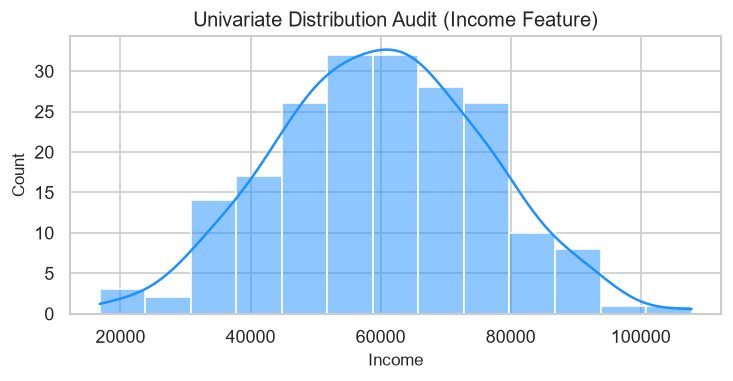

In [11]:
np.random.seed(42)
df_eda = pd.DataFrame({
    'age': np.random.randint(18, 70, 200),
    'income': np.random.normal(60000, 15000, 200),
    'score': np.random.rand(200)
})

profile_summary = df_eda.describe().T[['mean', 'std','min','max']]
print(profile_summary)

# Visualization: Distribution overview
plt.figure(figsize=(7, 3))
sns.histplot(df_eda['income'], kde=True, color='dodgerblue') # kde : Kernel Density Estimate, shows the smoothed distribution of the data
plt.title('Univariate Distribution Audit (Income Feature)')
plt.xlabel('Income')
plt.show()

In [ ]:
# # we will use ydata-profiling for EDA profiling tools
# from ydata_profiling import ProfileReport
# np.random.seed(42)
# df_eda = pd.DataFrame({
#     'age': np.random.randint(18, 70, 200),
#     'income': np.random.normal(60000, 15000, 200),
#     'score': np.random.rand(200)
# })

# profile = ProfileReport(df_eda,title="EDA Profiling Report", explorative=True)
# profile.to_file("eda_profiling_report.html")

In [ ]:
# import sweetviz as sv
# np.random.seed(42)
# df_eda = pd.DataFrame({
#     'age': np.random.randint(18, 70, 200),
#     'income': np.random.normal(60000, 15000, 200),
#     'score': np.random.rand(200)
# })
# report = sv.analyze(df_eda)
# report.show_html("sweetviz_report.html")

2. Automated Quality and Integrity Audits

In [14]:
df_audit = pd.DataFrame({
    'id': [1, 2, 2, 4, 5],
    'status': ['Active', 'Pending', 'Pending', 'Closed', None],
    'amount': [100, 200, 200, -50, 500]
})
# print(df_audit)

null_counts = df_audit.isnull().sum()
duplicate_counts = df_audit.duplicated().sum()
print("Null counts per column:\n", null_counts)
print("Number of duplicate rows:", duplicate_counts)

Null counts per column:
 id        0
status    1
amount    0
dtype: int64
Number of duplicate rows: 1


3. Data Schema Validation with Pandas-Schema

Validation errors: ['Age cannot be negative']
Status counts: [np.int64(3), np.int64(1)]


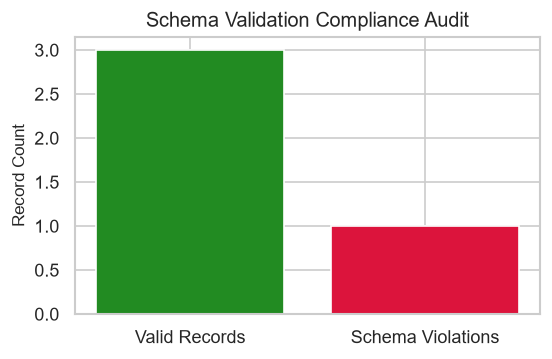

In [37]:
# Custom schema validation function simulation
def validate_schema(df):
    errors = []
    if not pd.api.types.is_integer_dtype(df['age']):
        errors.append('Age must be integer')
    if (df['age'] < 0).any():
        errors.append('Age cannot be negative')
    return errors

df_test = pd.DataFrame({'age': [25, 30, -5, 45]})
validation_errors = validate_schema(df_test)
print("Validation errors:", validation_errors)
proper_age_count = (df_test['age'] >= 0).sum()
improper_age_count = (df_test['age'] < 0).sum()
status_counts= [proper_age_count, improper_age_count]

print("Status counts:", status_counts)

plt.figure(figsize=(5, 3))
plt.bar(['Valid Records', 'Schema Violations'], status_counts, color=['forestgreen', 'crimson'])
plt.ylabel('Record Count')
plt.title('Schema Validation Compliance Audit')
plt.show()


4. Dataset Overview Summaries

In [41]:
df_overview = pd.DataFrame({
    'col_int': [1, 2, 3],
    'col_float': [1.1, 2.2, 3.3],
    'col_str': ['A', 'B', 'C']
})

dtype_counts = df_overview.dtypes.value_counts()
print("Data type counts:\n", dtype_counts)


Data type counts:
 int64      1
float64    1
str        1
Name: count, dtype: int64


---
## Summary Table

| Profiling & Audit Technique | Primary Tool / Method | Core Output / Metric | Primary Analytical Purpose |
| :--- | :--- | :--- | :--- |
| **Automated Profiling** | YData-Profiling / Sweetviz | Comprehensive univariate & bivariate reports | Instant visual & statistical data exploration |
| **Quality & Integrity Audits** | Custom checks / `isnull()` / `duplicated()` | Null ratios, duplicate counts, anomalies | Catching data corruption & structural defects |
| **Schema Validation** | Pandas-Schema / Custom rules | Rule pass/fail status per record | Enforcing strict data contracts & pipeline safety |
| **Dataset Overview Summaries**| `df.info()`, `dtypes`, memory usage | Shape dimensions & RAM footprint telemetry | High-level structural sanity check during ingest |